In [1]:
import os
import json
import sys
import time
import numpy as np
import pandas as pd
from datetime import datetime
import copy
import matplotlib.pyplot as plt

sys.path.insert(0, "..")

from numeric_method.numeric_method import solve_navier_stokes
from scipy.interpolate import RegularGridInterpolator

from analysis_functions import *

CASE_DIR = "./self_convergence_case.json"

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "text.latex.preamble": r"\usepackage{amsmath}",
})

miktex_bin = r"C:\Users\gkova\AppData\Local\Programs\MiKTeX\miktex\bin\x64"

if miktex_bin not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + miktex_bin
import shutil
# This check MUST return True for usetex to work
print(f"LaTeX found: {shutil.which('latex') is not None}")

LaTeX found: True


In [59]:
with open(CASE_DIR) as f:
    case_ = json.load(f)

original_size = 128
multipliers = [2, 1, 1/2, 1/4, 1/8]

results_u = []
results_p = []
boundaries = []

for i, multiplier in enumerate(multipliers):
    geom = [
        {
            "type": "outflow",
            "pos": { "x": int(multiplier * original_size - 1), "y": 0 },
            "size": { "width": 1, "height": int(multiplier * original_size) },
            "dir": { "x": -1, "y": 0 }
        },
        {
            "type": "inflow",
            "pos": { "x": 0, "y": 0 },
            "size": { "width": 1, "height": int(multiplier * original_size) },
            "vel": { "x": 0.1, "y": 0 }
        },
        {
            "type": "wall",
            "pos": { "x": 0, "y": 0 },
            "size": { "width": int(multiplier * original_size), "height": 1 },
            "dir": { "x": 0, "y": 1 }
        },
        {
            "type": "wall",
            "pos": { "x": 0, "y": int(multiplier * original_size - 1) },
            "size": { "width": int(multiplier * original_size), "height": 1 },
            "dir": { "x": 0, "y": -1 }
        },
        {
            "type": "wall",
            "pos": { "x": int(64 * multiplier), "y": int(64 * multiplier) },
            "size": { "width": int(32 * multiplier), "height": int(16 * multiplier) },
            "dir": { "x": 0, "y": 1 }
        },
        { "type": "cylinder", "pos": { "x": int(32 * multiplier), "y": int(32 * multiplier) }, "size": int(8 * multiplier) }
  ]
    
    _, _, _, _, _, _, boundary_mask = geometry_to_mtx(geom, int(original_size * multiplier), int(original_size * multiplier))

    u, p = solve_navier_stokes(
                int(original_size * multiplier),
                int(original_size * multiplier),
                case_["dx"] / multiplier,
                case_["dy"] / multiplier,
                1000,
                case_["time_step"],
                case_["density"],
                case_["viscosity"],
                case_["beta"],
                geom,
                dynamic_time_step=False,
                implicit_laplacian=False,
                return_div_u_star=False,
                method_type="numeric"
            )
    
    u = u[-1]
    p = p[-1]

    results_u.append(u)
    results_p.append(p)
    boundaries.append(boundary_mask)

	 -> Creating discrete Laplacian matrix...
	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 1000/1000 [03:22<00:00,  4.93it/s]


	 -> Creating discrete Laplacian matrix...
	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 1000/1000 [00:34<00:00, 29.26it/s]


	 -> Creating discrete Laplacian matrix...
	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 1000/1000 [00:06<00:00, 154.13it/s]


	 -> Creating discrete Laplacian matrix...
	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 1000/1000 [00:01<00:00, 536.31it/s]


	 -> Creating discrete Laplacian matrix...
	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 1000/1000 [00:00<00:00, 1439.10it/s]


In [73]:
def interpolate(coarse_data, fine_shape):
    x_coarse = np.linspace(0, 1, coarse_data.shape[0])
    y_coarse = np.linspace(0, 1, coarse_data.shape[1])
    
    interp_func = RegularGridInterpolator((x_coarse, y_coarse), coarse_data, method='cubic')
    
    x_fine = np.linspace(0, 1, fine_shape[0])
    y_fine = np.linspace(0, 1, fine_shape[1])
    X_fine, Y_fine = np.meshgrid(x_fine, y_fine, indexing='ij')
    
    pts = np.array([X_fine.ravel(), Y_fine.ravel()]).T
    return interp_func(pts).reshape(fine_shape)

errors_u = [0]
errors_p = [0]

u_baseline = results_u[0]
p_baseline = results_p[0][..., None]

bound = boundaries[0]

denom_u = L1(u_baseline, np.zeros_like(u_baseline))[bound != 1].sum()
denom_p = L1(p_baseline, np.zeros_like(p_baseline))[bound != 1].sum()

for i in range(1, len(multipliers)):
    u_interp = interpolate(results_u[i], u_baseline.shape)
    p_interp = interpolate(results_p[i], p_baseline.shape)

    err_u = L1(u_baseline, u_interp)
    err_p = L1(p_baseline, p_interp)

    err_u = err_u[bound != 1]
    err_p = err_p[bound != 1]

    errors_u.append(err_u.sum() / denom_u)
    errors_p.append(err_p.sum() / denom_p)

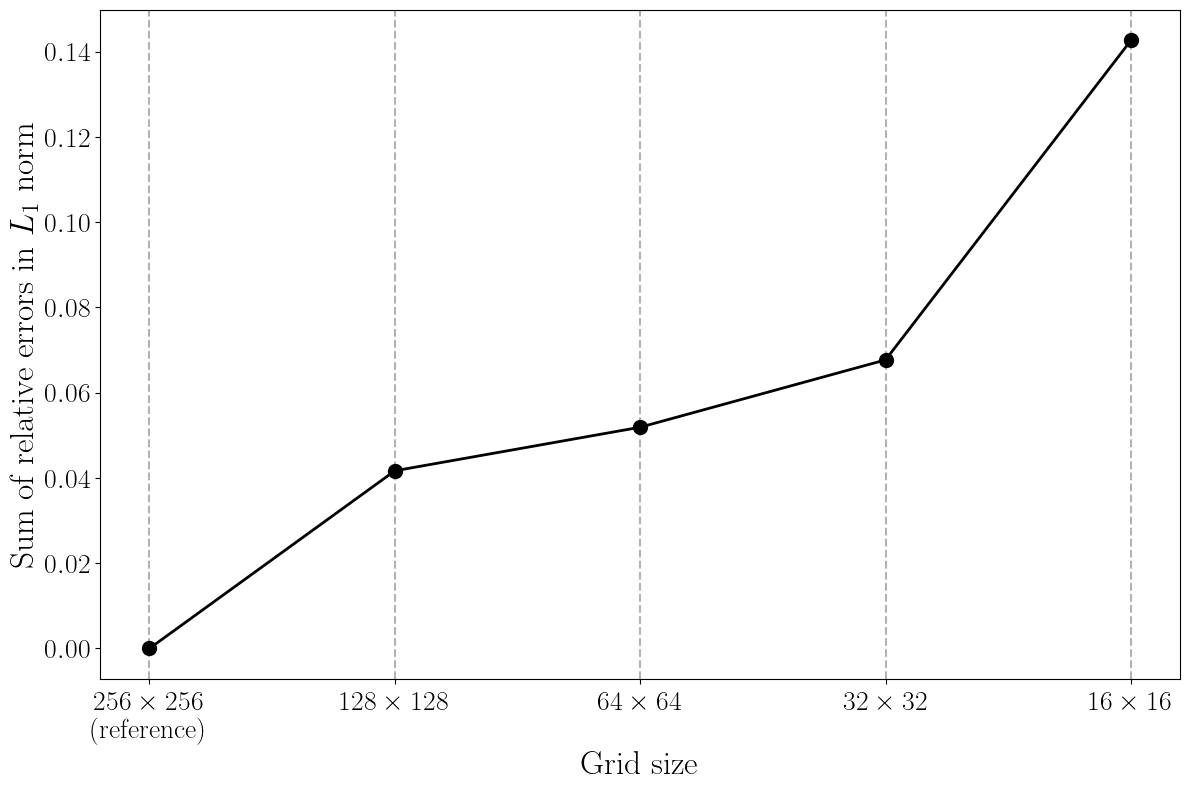

In [74]:
fig, ax = plt.subplots(figsize=(12, 8))

idx = [i for i in range(len(multipliers))]

ax.plot(errors_u, color="black", linewidth=2)
ax.scatter(idx, errors_u, color="black", s=100)

ax.set_xticks([i for i in range(len(multipliers))])

x_labels = []

for i, x_ in enumerate(original_size * np.array(multipliers)):
    txt = rf"${int(x_)} \times {int(x_)}$"
    if i == 0:
        txt += "\n(reference)"

    x_labels.append(txt)

    ax.axvline(i, 0, 3, color="black", alpha=0.3, linestyle="--", zorder=0)

ax.set_xticklabels(x_labels)

ax.tick_params(axis='both', which='major', labelsize=20)

ax.set_xlabel("Grid size", fontsize=24)
ax.set_ylabel("Sum of relative errors in $L_1$ norm", fontsize=24)

plt.tight_layout()
plt.savefig("self_conv_u.pdf")

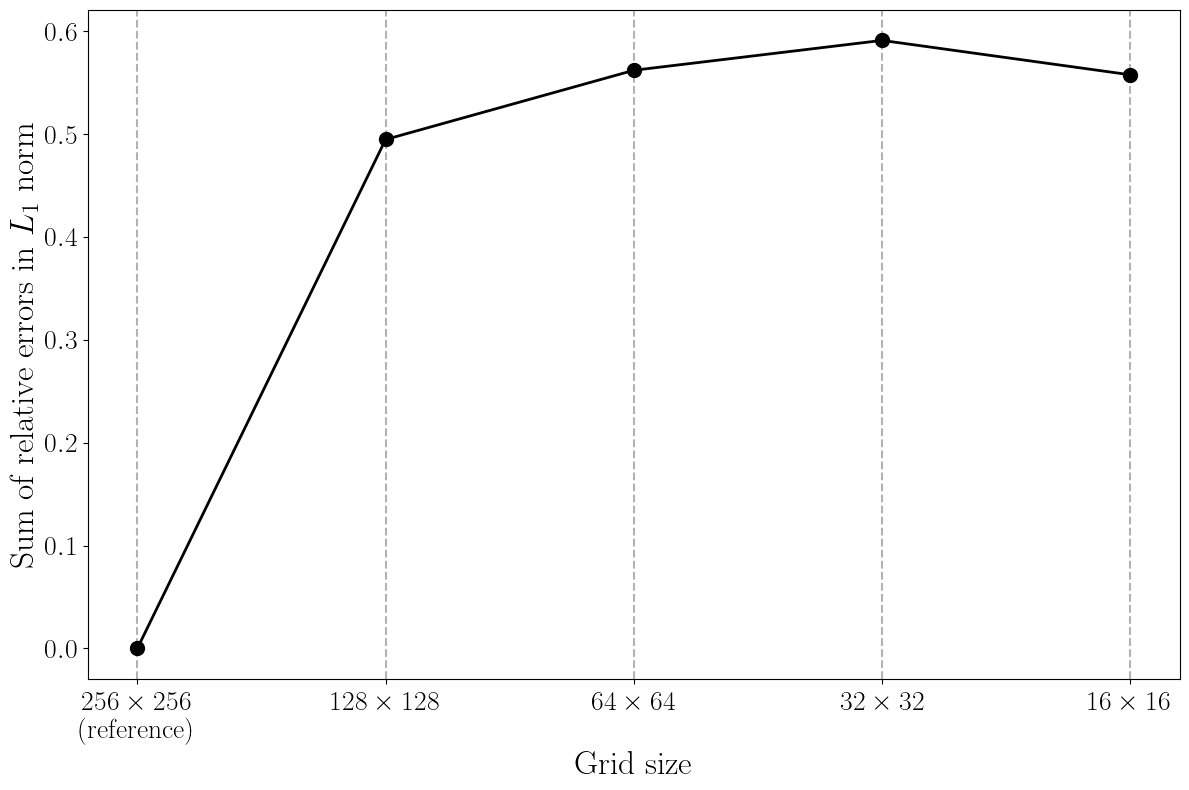

In [75]:
fig, ax = plt.subplots(figsize=(12, 8))

idx = [i for i in range(len(multipliers))]

ax.plot(errors_p, color="black", linewidth=2)
ax.scatter(idx, errors_p, color="black", s=100)

ax.set_xticks([i for i in range(len(multipliers))])

x_labels = []

for i, x_ in enumerate(original_size * np.array(multipliers)):
    txt = rf"${int(x_)} \times {int(x_)}$"
    if i == 0:
        txt += "\n(reference)"

    x_labels.append(txt)

    ax.axvline(i, 0, 3, color="black", alpha=0.3, linestyle="--", zorder=0)

ax.set_xticklabels(x_labels)

ax.tick_params(axis='both', which='major', labelsize=20)

ax.set_xlabel("Grid size", fontsize=24)
ax.set_ylabel("Sum of relative errors in $L_1$ norm", fontsize=24)

plt.tight_layout()
plt.savefig("self_conv_p.pdf")

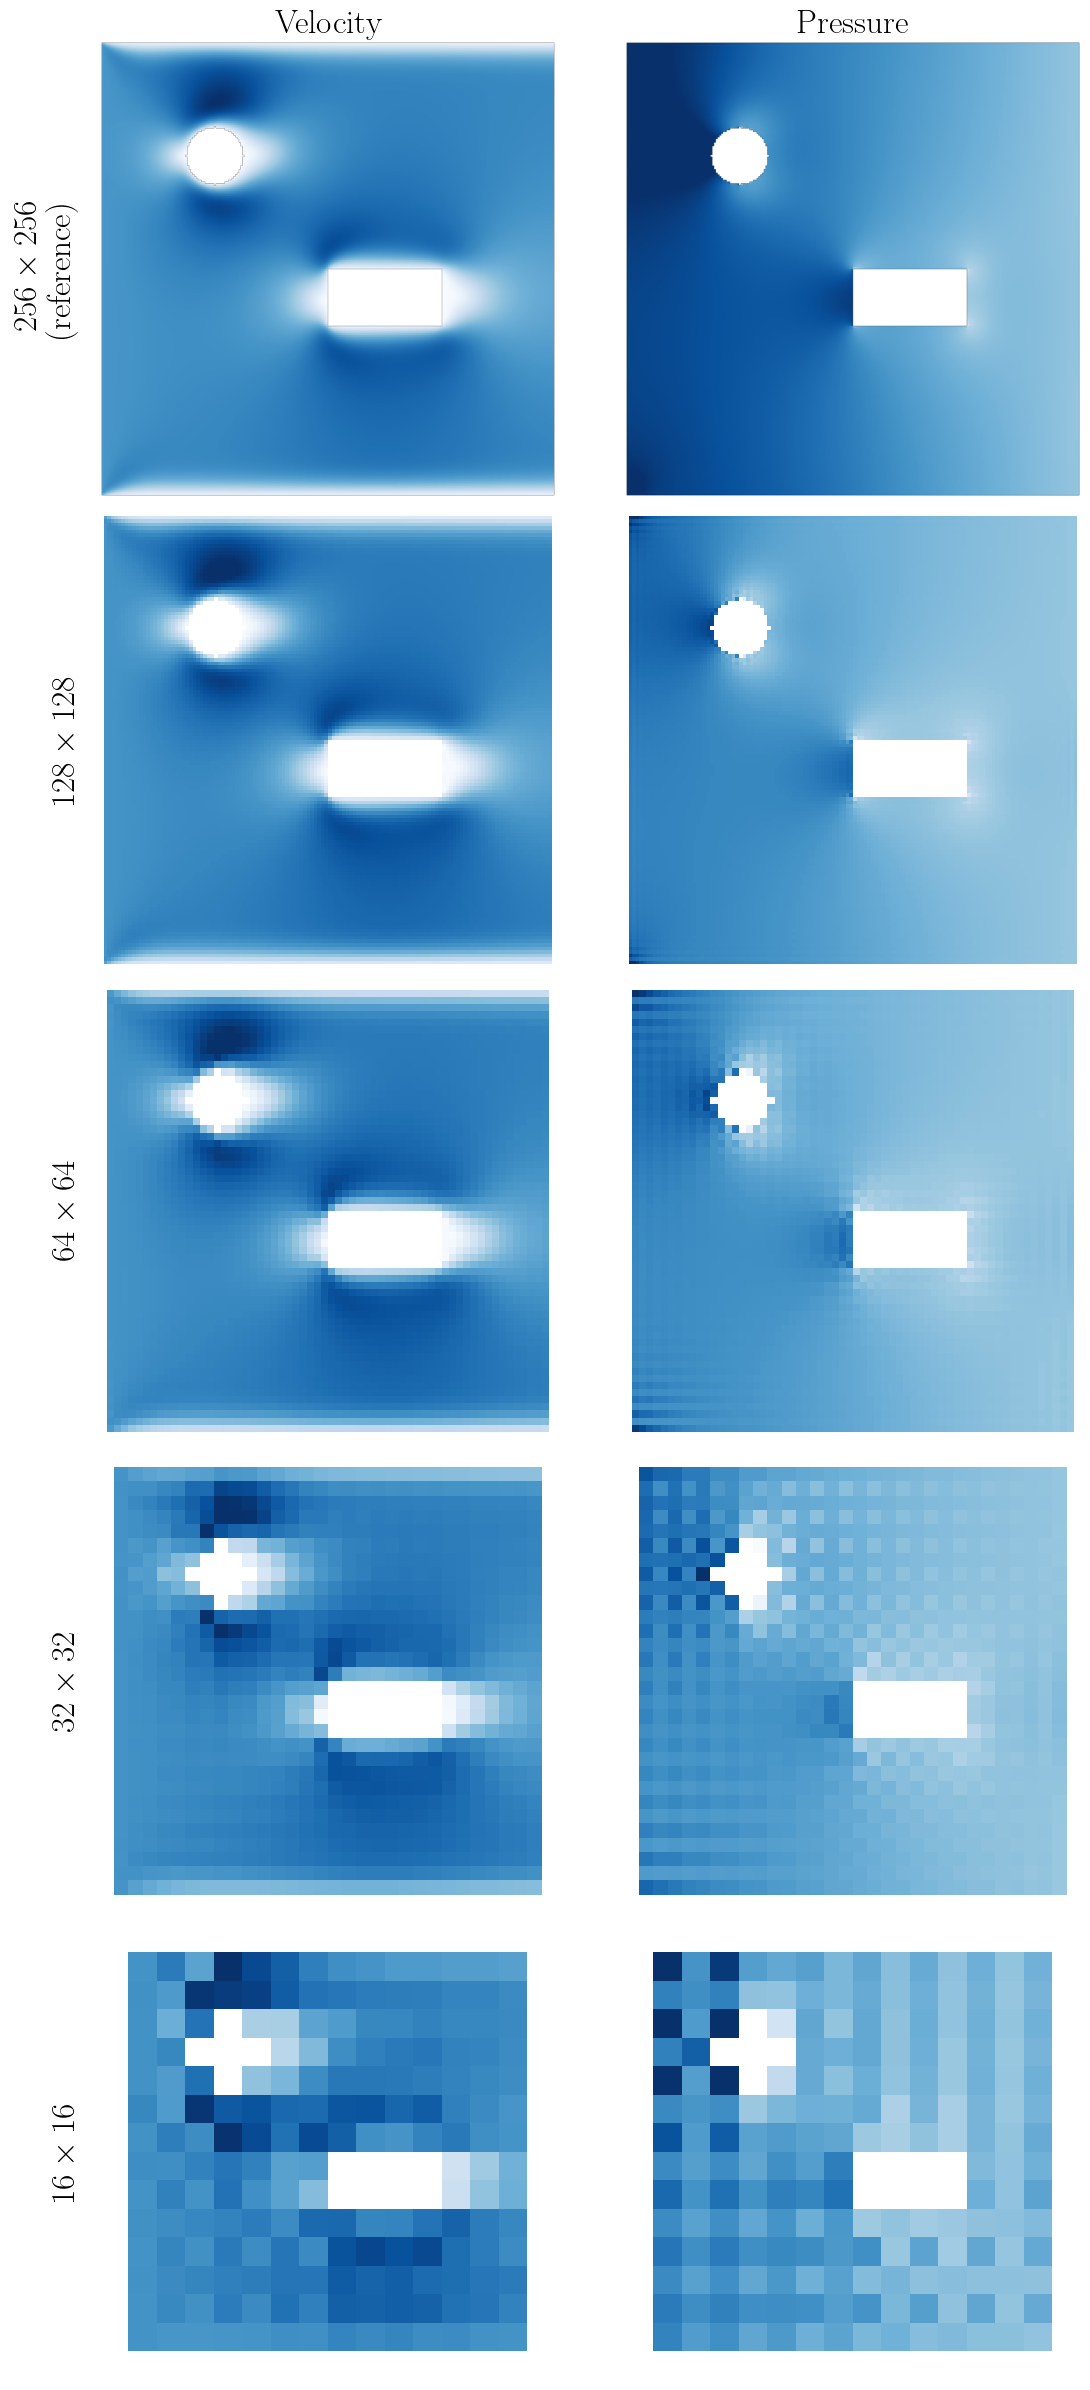

In [63]:
fig, ax = plt.subplots(5, 2, figsize=(12, 24))

umin = np.inf
umax = -np.inf
pmin = np.inf
pmax = -np.inf

for i in range(len(results_u)):
    bound = boundaries[i]
    u_ = np.sqrt(results_u[i][..., 0] ** 2 + results_u[i][..., 1] ** 2) * (1 - bound)
    p_ = results_p[i] * (1 - bound)

    if i == 0 or u_.min() < umin:
        umin = u_.min()

    if i == 0 or u_.max() < umax:
        umax = u_.max()

    if i == 0 or p_.min() < pmin:
        pmin = p_.min()

    if i == 0 or p_.max() < pmax:
        pmax = p_.max()

from matplotlib.colors import ListedColormap
bw_map = ListedColormap([(0, 0, 0, 0), (1, 1, 1, 1)])

for i in range(len(results_u)):
    bound = boundaries[i]
    
    ax[i, 0].imshow(np.sqrt(results_u[i][..., 0] ** 2 + results_u[i][..., 1] ** 2) * (1 - bound), cmap="Blues", vmin=umin, vmax=umax)
    ax[i, 1].imshow(results_p[i] * (1 - bound), cmap="Blues", vmin=pmin, vmax=pmax)

    ax[i, 0].imshow(bound, cmap=bw_map)
    ax[i, 1].imshow(bound, cmap=bw_map)

    ax[i, 0].set_axis_off()
    ax[i, 1].set_axis_off()

    txt = fr"${int(original_size * multipliers[i])} \times {int(original_size * multipliers[i])}$"
    if i == 0:
        txt += "\n(reference)"
        
    ax[i, 0].annotate(txt, xy=(-0.05, 0.5), xycoords='axes fraction', 
                      rotation=90, va='center', ha='right', 
                      fontsize=24)

ax[0, 0].set_title("Velocity", fontsize=24)
ax[0, 1].set_title("Pressure", fontsize=24)

plt.tight_layout()

plt.savefig("self_conv_vel_press.pdf")